# Genetic Algorithm - Real-Valued Parameters: experimental results

The experimental benchmark covers three standard functions in **10 dimensions ($D=10$)**:
- **Schwefel Function:** Highly multimodal and deceptive search landscape with global minimum at $\mathbf{x}^* = (420.9687, \dots, 420.9687)$, $f(\mathbf{x}^*) = 0.0$.
- **Sphere Function:** Smooth, unimodal, convex benchmark with global minimum at $\mathbf{x}^* = (0, \dots, 0)$, $f(\mathbf{x}^*) = 0.0$.
- **Rosenbrock Function:** Non-separable function featuring a steep curved parabolic valley with global minimum at $\mathbf{x}^* = (1, \dots, 1)$, $f(\mathbf{x}^*) = 0.0$.


## Experimental Configuration

| Parameter | Value | Description |
|---|---:|---|
| **Dimensionality ($D$)** | 10 | 10-dimensional continuous search space |
| **Evaluation budget** | 10,000 FES | Stopping criterion per run |
| **Independent runs** | 10 | Statistical sample size per variant |
| **Population size** | 100 | Individuals per generation |
| **Elitism ratio** | 0.10 | Preserves top 10% best individuals |
| **Crossover ratio** | 0.90 | Probability of crossover |
| **Mutation probability** | 0.05 | Per-bit (binary) or per-dimension (real) |
| **Parent selection** | Tournament ($k=3$) | Tournament selection for minimization |
| **Gaussian $\sigma$** | $0.10 \times (hi - lo)$ | Standard deviation for Gaussian mutation |
| **Base random seed** | 42 | Reproducibility base seed |

Five algorithm variants are evaluated:
1. **IEEE 754 Binary:** 32 bits/dim single-precision float (sign, 8 exponent, 23 mantissa), single-point bit crossover, bit-flip mutation.
2. **Fixed-Point Binary:** 32 bits/dim linear integer mapping into $[0, 2^{32}-1]$, uniform resolution, single-point bit crossover, bit-flip mutation.
3. **BCD Binary:** 32 bits/dim (8 decimal digits, 4 bits each), invalid nibble repair (clamping 10-15 to 9), bit-flip mutation.
4. **Real-Valued (Gaussian Mutation):** Dimension-level single-point crossover, perturbation $x_i + \mathcal{N}(0, \sigma^2)$ clamped to bounds.
5. **Real-Valued (Uniform Mutation):** Dimension-level single-point crossover, random uniform resampling $x_i \sim \mathcal{U}(lo, hi)$.


In [2]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
results_path = root / "results.json"
if not results_path.exists():
    raise FileNotFoundError(
        f"Expected {results_path}. Run main.py with result saving enabled first. (--save-results flag)"
    )

results = json.loads(results_path.read_text(encoding="utf-8"))
print("Loaded benchmark functions:", list(results.keys()))

Loaded benchmark functions: ['schwefel', 'sphere', 'rosenbrock']


## Summary Statistics

The table below presents the statistical distribution of the best fitness obtained at 10,000 FES over 10 independent runs for each combination of benchmark function and GA variant.
All problems are **minimization** tasks (lower values represent better solutions).


In [6]:
from modules.ga_engine import VARIANT_NAMES

rows = []
for func_name, variants in results.items():
    for var_key, var_data in variants.items():
        stats = var_data["statistics"]
        rows.append(
            {
                "Function": func_name.capitalize(),
                "Variant": VARIANT_NAMES.get(var_key, var_key),
                "FES Budget": 10000,
                "Best": round(stats["best"], 4),
                "Worst": round(stats["worst"], 4),
                "Mean": round(stats["mean"], 4),
                "Median": round(stats["median"], 4),
                "StdDev": round(stats["stddev"], 4),
            }
        )

summary_df = pd.DataFrame(rows)
summary_df

,Function,Variant,FES Budget,Best,Worst,Mean,Median,StdDev
0,Schwefel,IEEE 754 Binary,10000,1669.1789,2036.7195,1873.1781,1908.1736,106.1011
1,Schwefel,Fixed-Point Binary,10000,26.1920,254.4643,75.2359,58.1790,65.3722
2,Schwefel,BCD Binary,10000,4.7534,24.6575,15.5762,16.5497,6.6448
3,Schwefel,Real-Valued (Gaussian Mutation),10000,118.8845,357.5420,214.4290,237.4337,93.6989
4,Schwefel,Real-Valued (Uniform Mutation),10000,2.0484,21.4605,10.3575,9.9803,6.0817
5,Sphere,IEEE 754 Binary,10000,0.0000,0.0000,0.0000,0.0000,0.0000
6,Sphere,Fixed-Point Binary,10000,0.0425,0.1441,0.0770,0.0706,0.0316
7,Sphere,BCD Binary,10000,0.0115,0.2094,0.0718,0.0458,0.0656
8,Sphere,Real-Valued (Gaussian Mutation),10000,0.0002,0.0040,0.0016,0.0012,0.0012
9,Sphere,Real-Valued (Uniform Mutation),10000,0.0057,0.0388,0.0142,0.0094,0.0103


### Interpretation of Summary Statistics

1. **Schwefel Function:**
   - **Real-Valued (Uniform Mutation)** achieved the best overall result ($	ext_{mean} = 10.36$, $	ext_{best} = 2.05$). The ability of uniform mutation to perform large jumps across the wide $[-500, 500]^{10}$ domain enables individuals to escape deceptive local minima.
   - **BCD Binary** ranked second ($	ext_{mean} = 15.58$), benefiting from digit-level decimal scaling.
   - **Fixed-Point Binary** reached a mean of $75.24$ with high standard deviation ($65.37$), reflecting susceptibility to Hamming cliffs.
   - **Real-Valued (Gaussian Mutation)** stagnated at $	ext_{mean} = 214.43$. Because $\sigma$ is localized ($10\%$ of range), once the population drops into a local valley, the probability of a $>3\sigma$ step landing in the global basin is negligible.
   - **IEEE 754 Binary** failed catastrophically ($	ext_{mean} = 1873.18$). Flipping exponent bits destroys the scale needed for $x_{i} \approx 420.97$.

2. **Sphere Function:**
   - **IEEE 754 Binary** achieved $	ext_{mean} = 0.0000$. Because the optimum is at the origin $(0, \dots, 0)$, the exponential concentration of floating-point representations near zero accelerates convergence dramatically.
   - **Real-Valued (Gaussian Mutation)** placed second ($	ext_{mean} = 0.0016$), smoothly exploiting the convex gradient.
   - **Real-Valued (Uniform Mutation)** followed with $	ext_{mean} = 0.0142$. Frequent uniform replacements disrupt near-optimal coordinates.
   - **Fixed-Point and BCD** reached $	ext_{mean} \approx 0.07$, bounded by discretization resolution and Hamming barriers.

3. **Rosenbrock Function:**
   - Both **Real-Valued Gaussian** and **Real-Valued Uniform** achieved the best solutions ($	ext_{mean} \approx 6.72$, $	ext_{best} \approx 1.85\ and\ 2.26$). Continuous vector adjustments allow individuals to track the curved parabolic valley $x_{i+1} \approx x_i^2$.
   - **Fixed-Point** and **IEEE 754** achieved $	ext_{mean} \approx 8.41\ and\ 8.43$.
   - **BCD Binary** struggled ($	ext_{mean} = 16.40, 	ext_{std} = 11.09$) because decimal digit flips produce abrupt step changes that throw points onto the steep canyon walls.


## Average Convergence: Schwefel Function

The plot shows the average best-so-far fitness trace over 10 runs for all 5 GA variants on the 10D Schwefel problem.


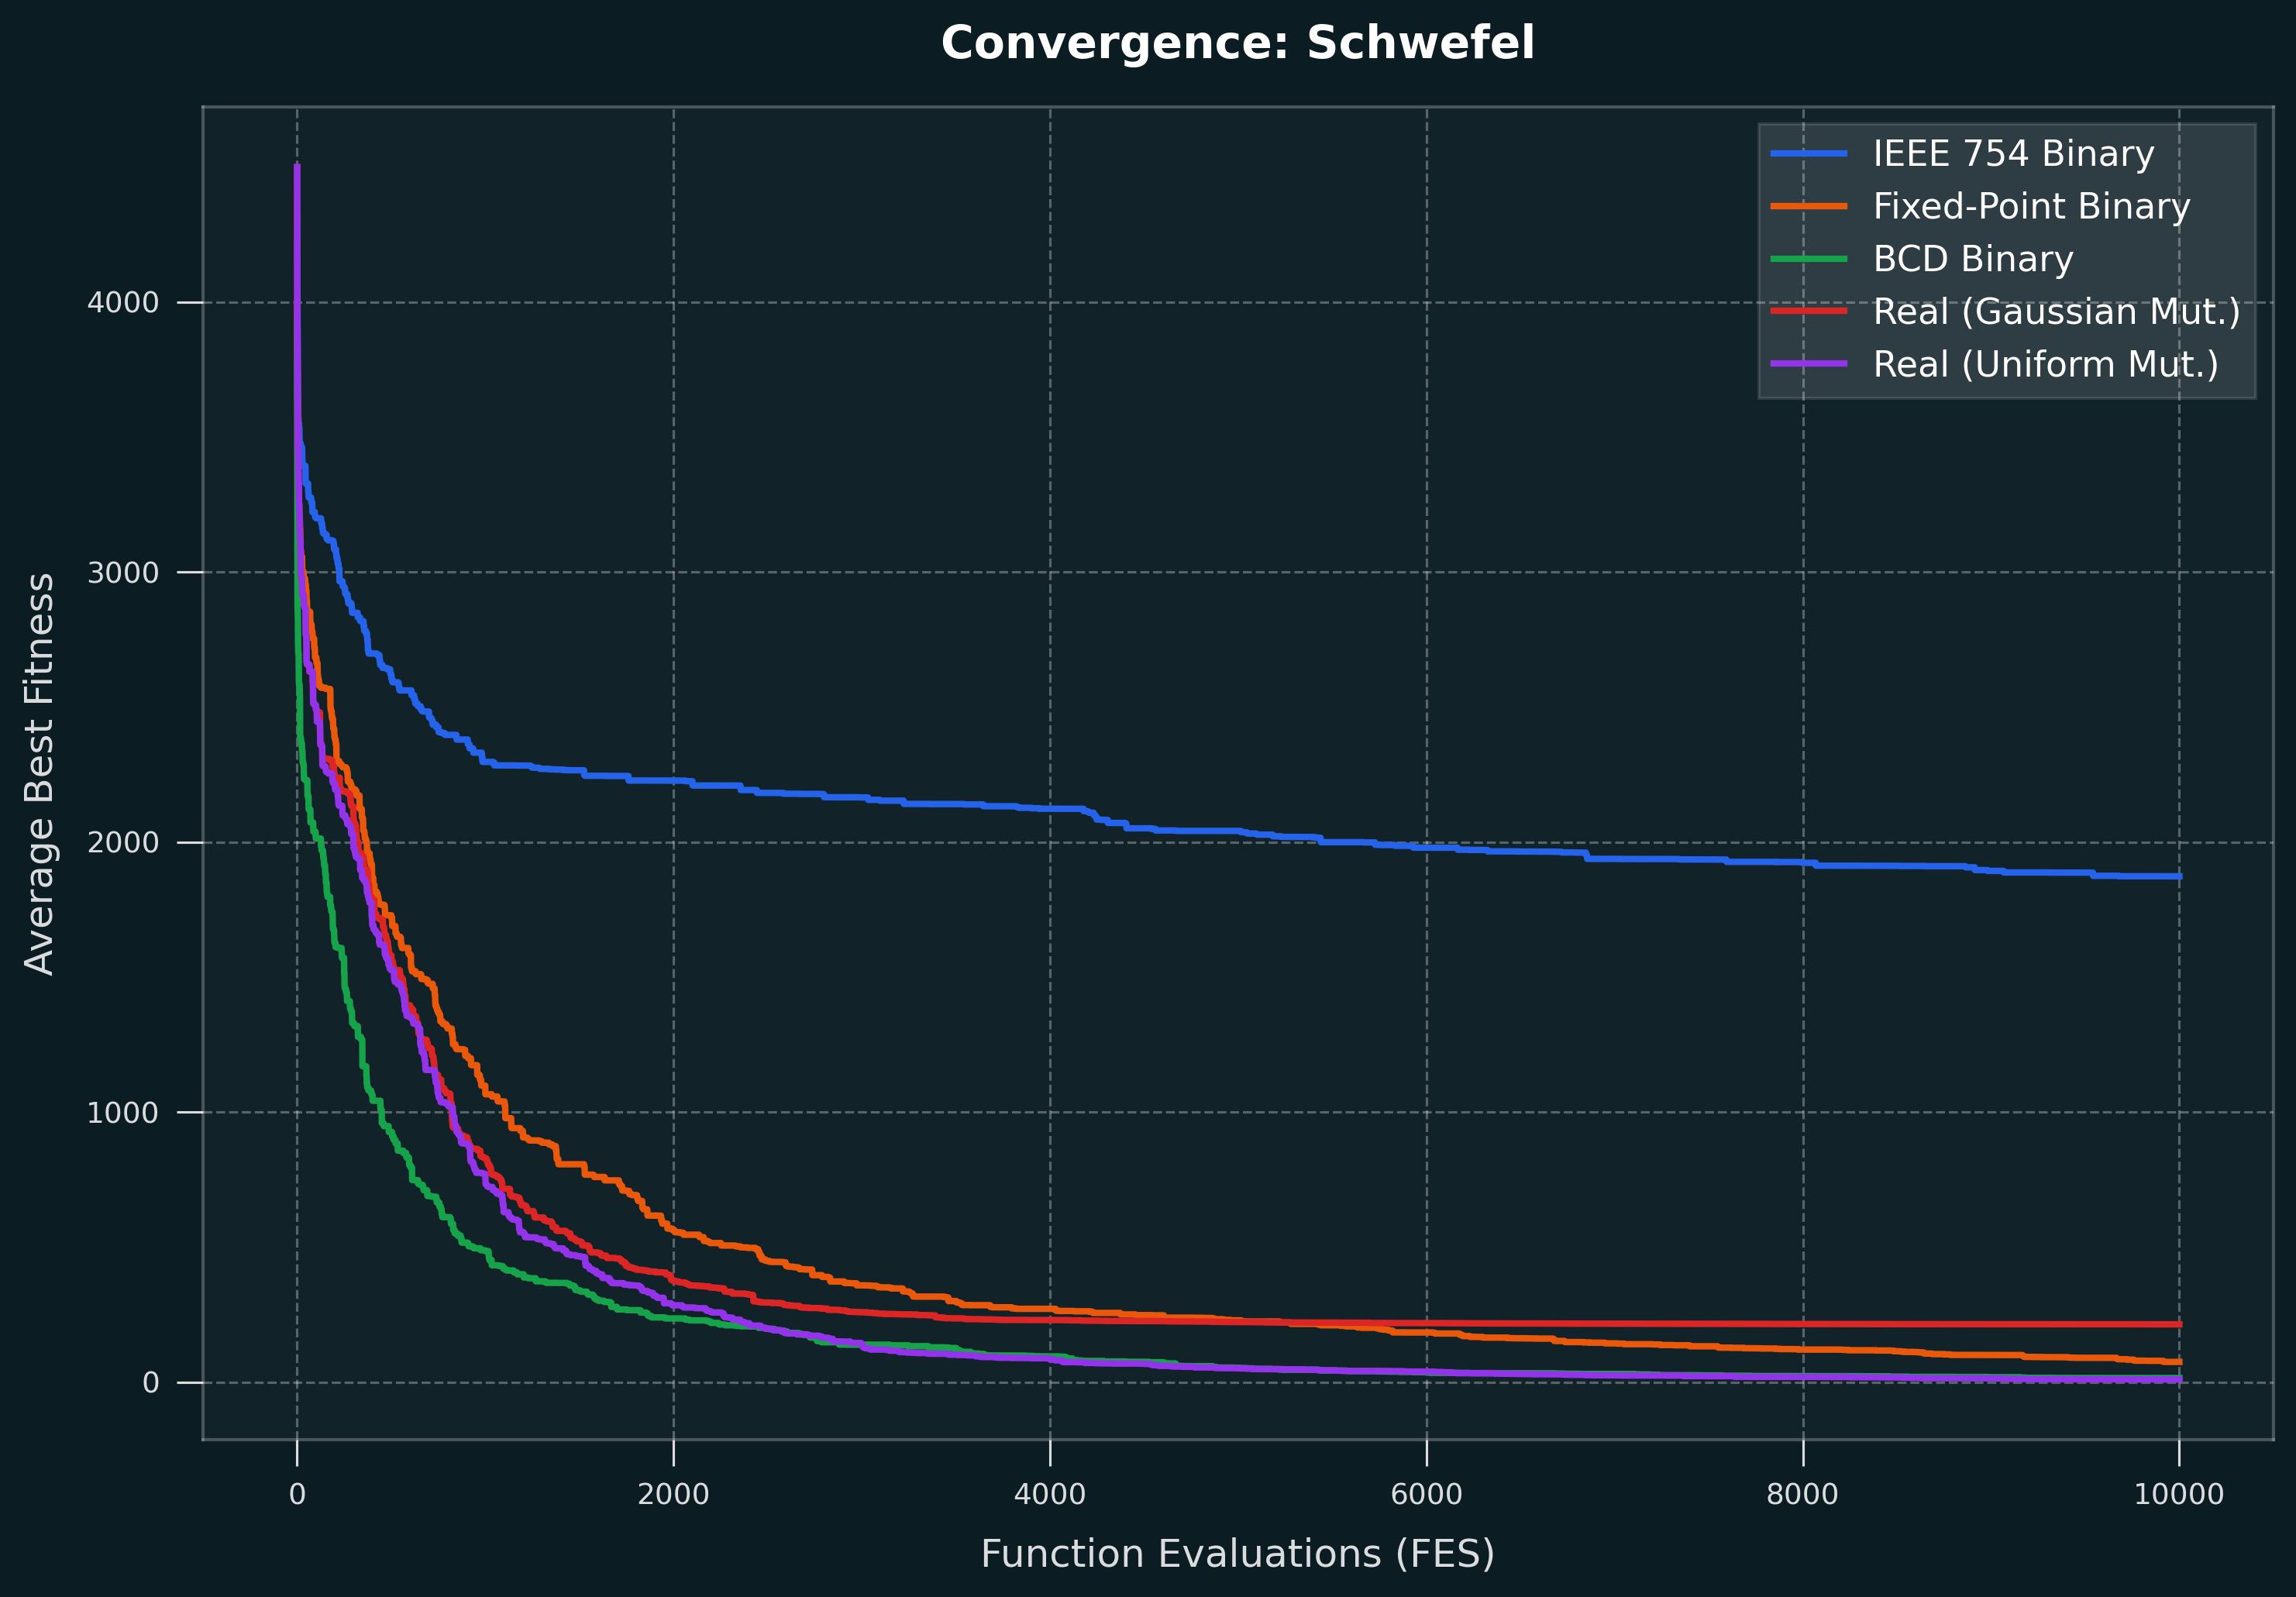

In [7]:
display(Image(filename="img/convergence/convergence_schwefel.png"))

### Schwefel Convergence Analysis

- **Real-Valued (Uniform Mutation)** drops rapidly within the first 2,000 FES and continues to refine toward $10.36$. Its global exploratory operator acts as a continuous restart mechanism for individual dimensions, easily avoiding deceptive basins.
- **BCD Binary** shows smooth, step-like improvements, as higher decimal digits are fixed first, followed by lower-significance digits.
- **Real-Valued (Gaussian Mutation)** flattens early around 3,000 FES, caught in suboptimal basins.
- **IEEE 754 Binary** exhibits almost no meaningful progress after the initial 1,000 evaluations. In binary floating point, an exponent flip multiplies the coordinate by a power of two, completely destabilizing the search.


## Average Convergence: Sphere Function

The plot shows the average best-so-far fitness trace over 10 runs for all 5 GA variants on the 10D Sphere problem.


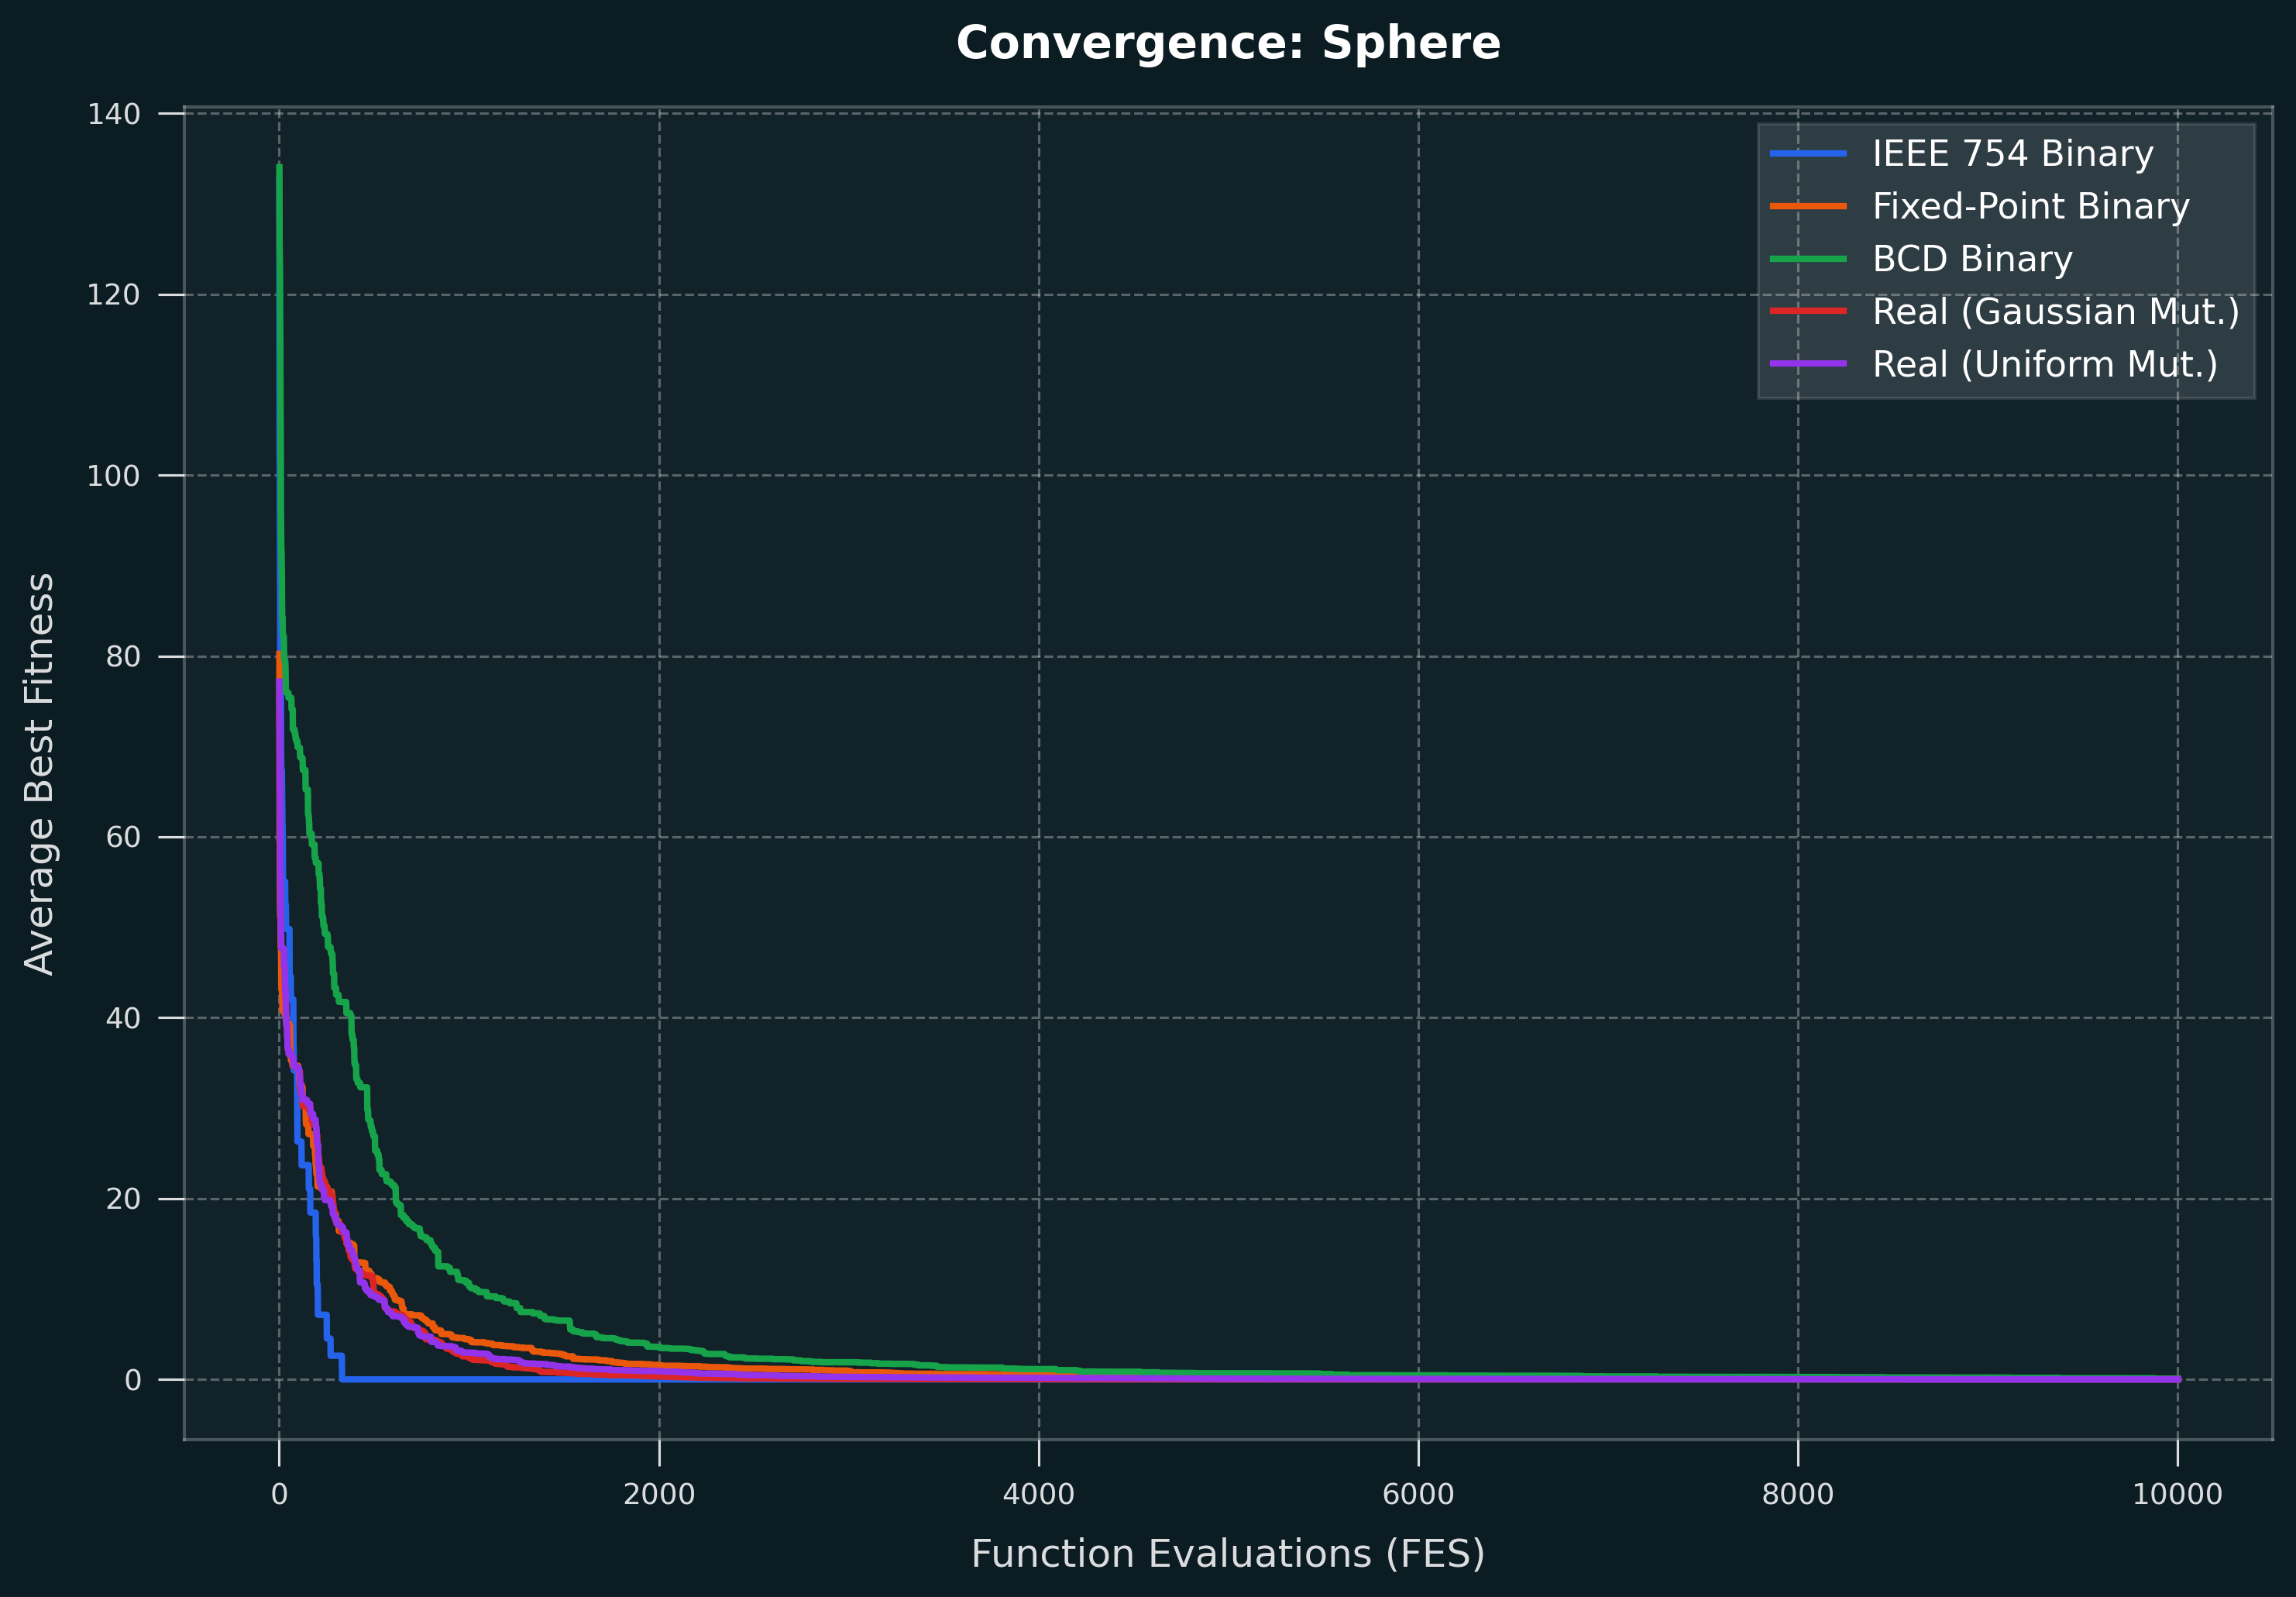

In [8]:
display(Image(filename="img/convergence/convergence_sphere.png"))

### Sphere Convergence Analysis

- **IEEE 754 Binary** exhibits instant, vertical descent toward zero on a linear scale.
- **Real-Valued (Gaussian Mutation)** shows the classic exponential decay characteristic of evolutionary strategies on convex landscapes.
- **Real-Valued (Uniform Mutation)** and the binary variants (**Fixed-Point** and **BCD**) plateau between $10^{-2}$ and $10^{-1}$, where mutation noise offsets selection pressure.


## Average Convergence: Rosenbrock Function

The plot shows the average best-so-far fitness trace over 10 runs for all 5 GA variants on the 10D Rosenbrock problem.


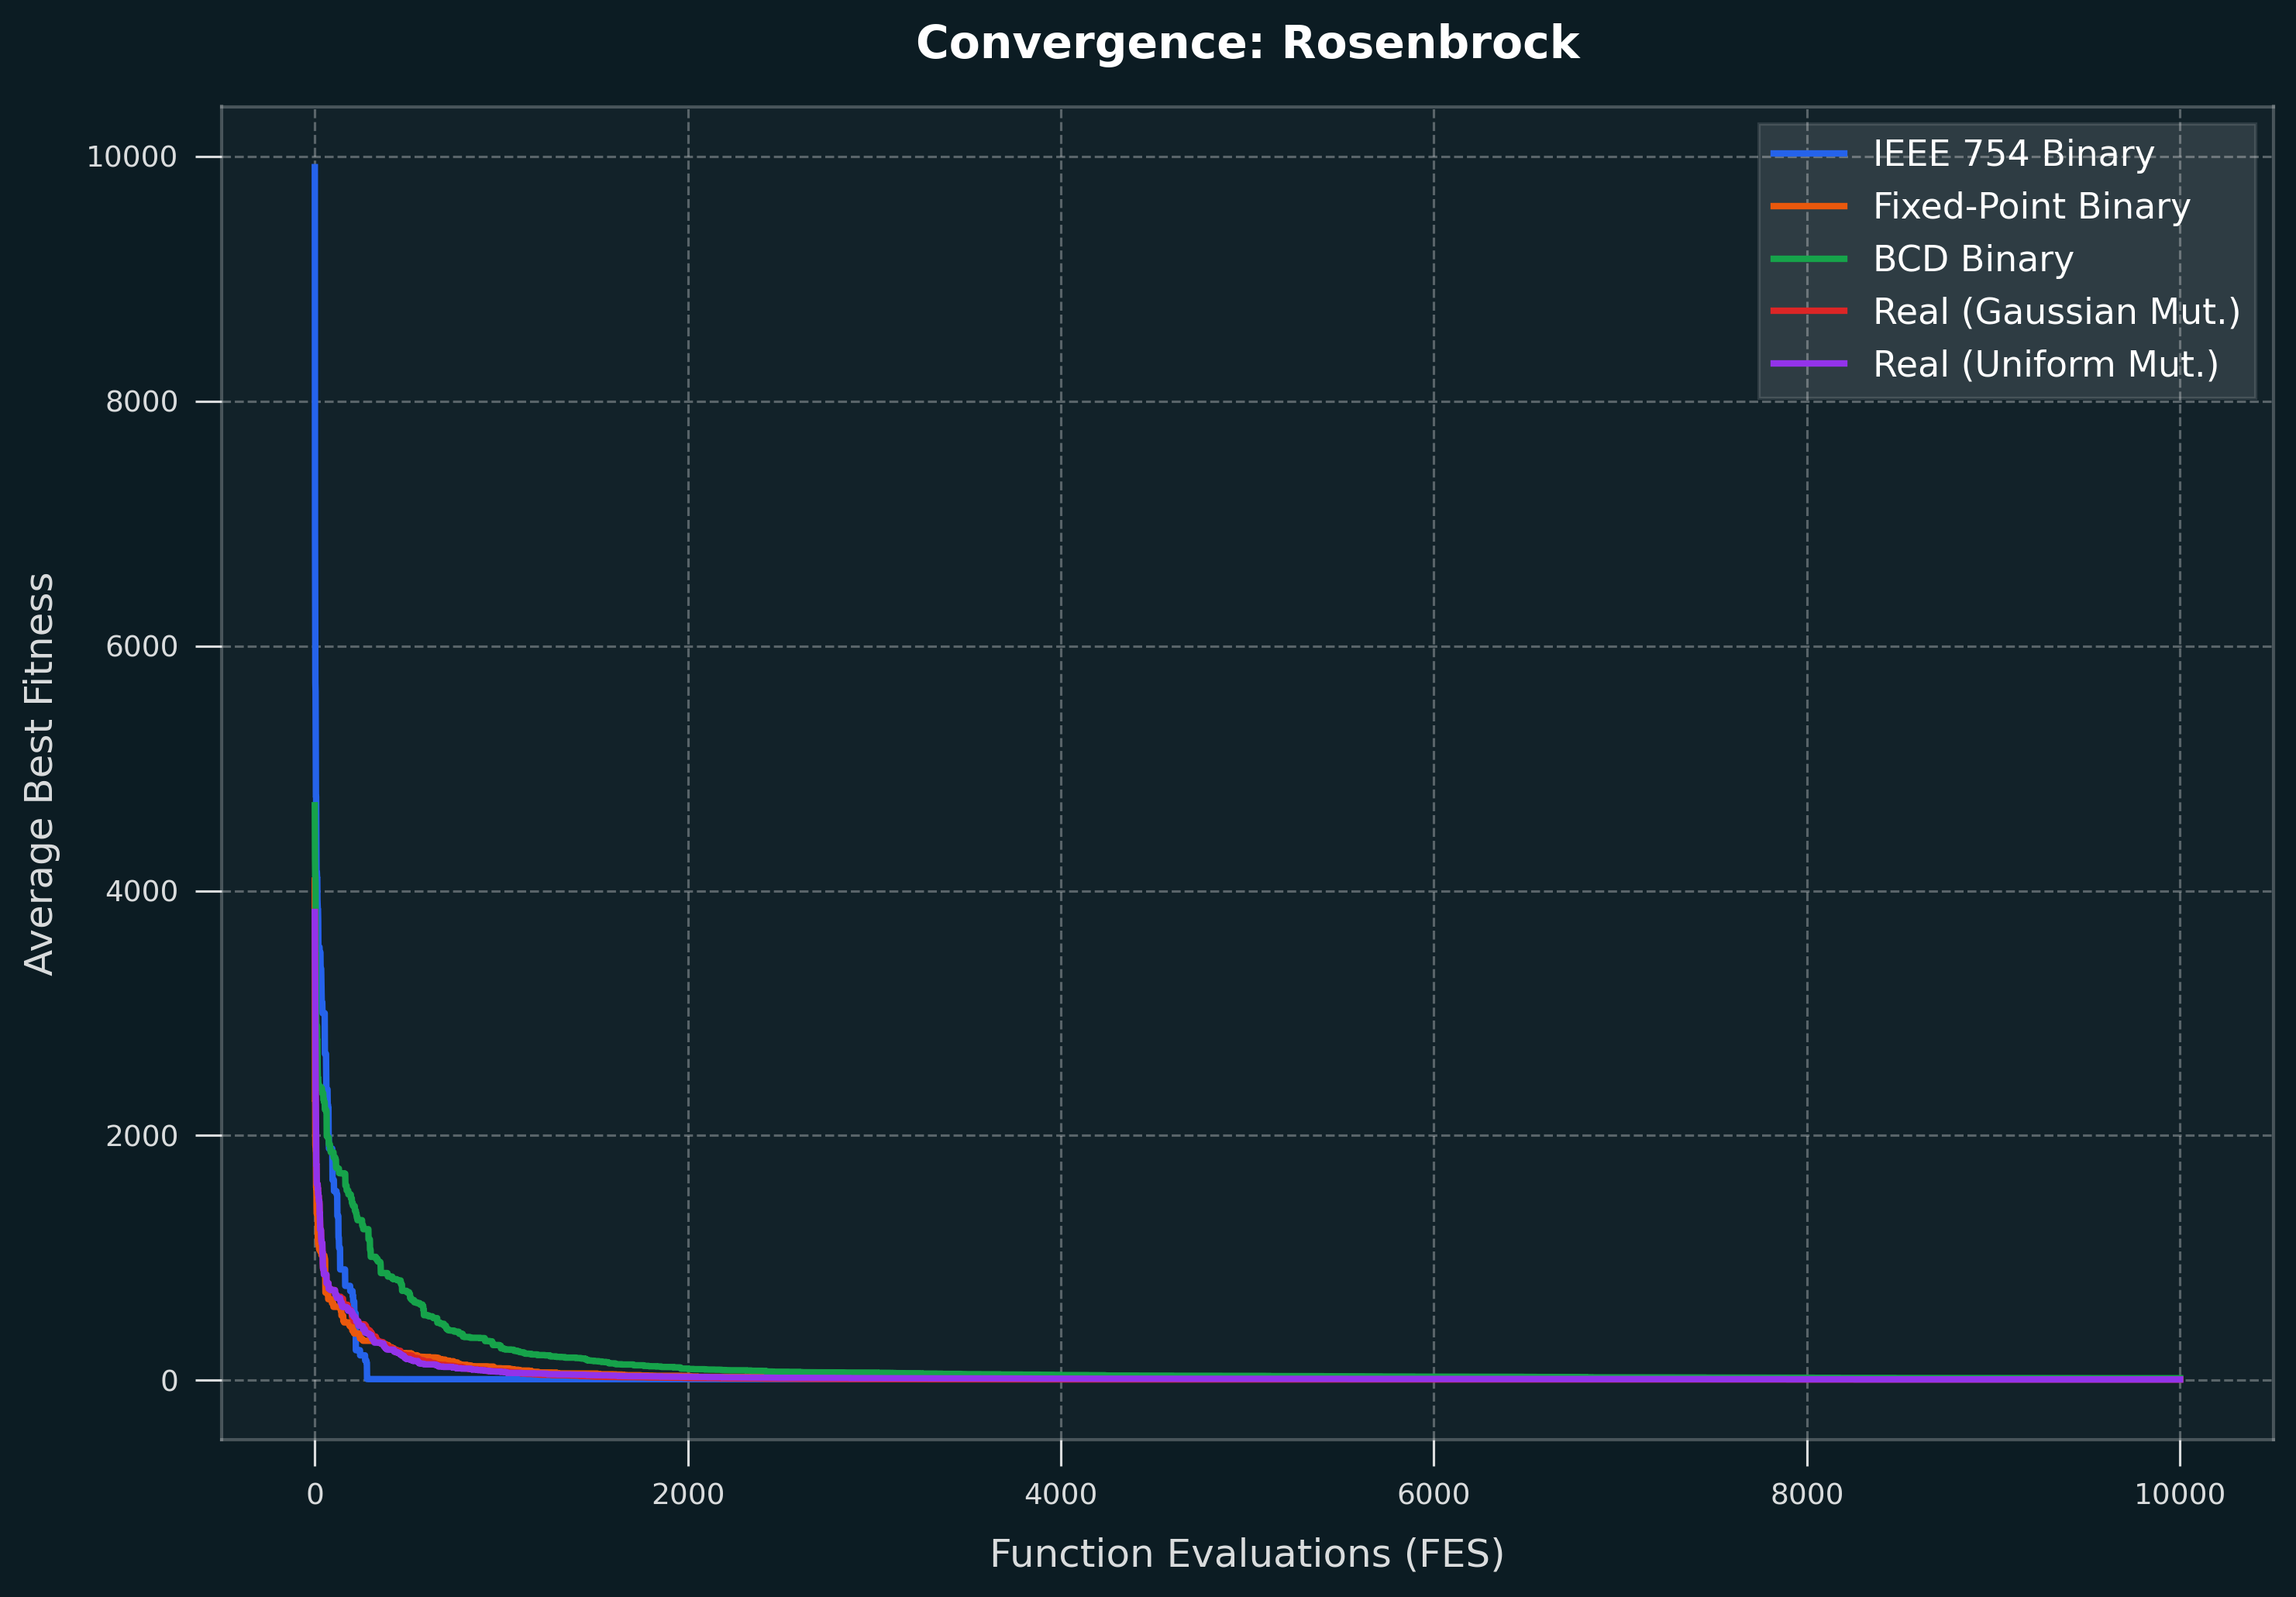

In [9]:
display(Image(filename="img/convergence/convergence_rosenbrock.png"))

### Rosenbrock Convergence Analysis

- The Rosenbrock landscape features a steep parabolic valley $x_{i+1} = x_i^2$ leading to the minimum at $(1, \dots, 1)$. Finding the valley is fast for all algorithms, causing the initial sharp drop in fitness.
- Progress along the valley floor requires coupled adjustments of adjacent dimensions. Real-valued variants navigate this coupled trajectory more effectively than binary representations, whose axis-aligned bit mutations frequently overshoot the valley floor.


## Comparative Ranking and Cross-Function Analysis


In [16]:
pivot_mean = summary_df.pivot(index="Variant", columns="Function", values="Mean")
rank_df = pivot_mean.rank(ascending=True)
pivot_mean["Average Rank"] = rank_df.mean(axis=1)
pivot_mean["Best Function"] = rank_df.idxmin(axis=1)
pivot_mean.sort_values(by="Average Rank")

Function,Rosenbrock,Schwefel,Sphere,Average Rank,Best Function
Variant,,,,,
Real-Valued (Uniform Mutation),6.7249,10.3575,0.0142,2.000000,Schwefel
Real-Valued (Gaussian Mutation),6.7167,214.4290,0.0016,2.333333,Rosenbrock
IEEE 754 Binary,8.4292,1873.1781,0.0000,3.333333,Sphere
Fixed-Point Binary,8.4121,75.2359,0.0770,3.666667,Rosenbrock
BCD Binary,16.4023,15.5762,0.0718,3.666667,Schwefel


## Theoretical Justification: Why Variants Perform Better or Worse

### 1. Representation Bias: IEEE 754 vs. Fixed-Point vs. Continuous
- **Floating-Point Non-Uniformity:** An IEEE 754 32-bit float devotes 1 bit to sign, 8 bits to the exponent, and 23 bits to the mantissa.
  - When the optimum is at zero (**Sphere**), shrinking the exponent produces infinitesimal step sizes. The representation possesses an inherent bias that guides mutations straight to the origin.
  - When the optimum is distant from zero (**Schwefel** at $x \approx 420.97$), any mutation in the 8 exponent bits causes massive multiplying/dividing excursions. This destroys the fine-tuning of the 23 mantissa bits, creating catastrophic instability.
- **Fixed-Point Uniformity:** Fixed-point encoding maps the range linearly to $[0, 2^{32}-1]$. The resolution $\Delta x = (hi - lo)/(2^{32}-1)$ is uniform everywhere. It avoids the zero-bias of IEEE 754, but introduces **Hamming cliffs** (e.g., crossing from $0111\dots1_2$ to $1000\dots0_2$ requires 32 simultaneous bit flips).

### 2. Genetic Operators: Local Exploitation vs. Global Exploration
- **Gaussian Mutation (Local Search):** Perturbations $x_i + \mathcal{N}(0, \sigma^2)$ are concentrated near the current position. This makes Gaussian mutation an exceptional **exploitation** operator on unimodal, convex landscapes (**Sphere**), but vulnerable to premature convergence on deceptive multimodal landscapes (**Schwefel**).
- **Uniform Mutation (Global Search):** Resampling $x_i \sim \mathcal{U}(lo, hi)$ ignores distance entirely. On multimodal functions with isolated deep basins (**Schwefel**), this provides the **exploration** capacity needed to jump between distant valleys, making it the top-performing variant on Schwefel.
- **Dimensionality Crossover:** Single-point crossover between dimensions for real-valued individuals swaps complete coordinate blocks without disrupting internal bit patterns, avoiding the high-order schema disruption seen in binary crossover.

### 3. Redundancy and Invalid States in BCD
- Binary-Coded Decimal uses 4 bits per decimal digit. However, 4 bits can represent 16 states ($0000_2$ to $1111_2$), while decimal digits only use 10 states ($0 \dots 9$).
- Consequently, $6/16 = 37.5\%$ of the raw genotype space corresponds to invalid codes. While the repair operator (clamping $10\dots15$ to $9$) prevents runtime crashes, it distorts the search distribution and reduces effective genetic diversity.

### Summary Conclusion
- **For unimodal / convex problems with optimum at 0:** IEEE 754 and Real-Valued Gaussian mutation are optimal.
- **For multimodal / deceptive problems:** Real-Valued Uniform mutation is vastly superior due to its strong global exploration capability.
- **For continuous optimization in general:** Direct real-valued representations eliminate Hamming cliffs, encoding/decoding overhead, and invalid state spaces, making them the most versatile choice overall.
